# Final project · ប្រព័ន្ធ FoodBridge របស់អ្នក

នៅសប្ដាហ៍ទី 2–8 អ្នកបានបង្កើតផ្នែកនីមួយៗនៃប្រព័ន្ធព័ត៌មានមួយ ម្ដងមួយៗ។ ឥឡូវ អ្នកផ្គុំវាបញ្ចូលគ្នា ជា **ប្រព័ន្ធផ្ទាល់ខ្លួនរបស់អ្នក**: វាដំណើរការសំណើផ្ដល់អាហារពេញមួយថ្ងៃ ធ្វើតាមការសម្រេចចិត្ត **របស់អ្នក** ហើយអ្នកអាចពន្យល់ និងប្រគល់ជម្រើសនីមួយៗបាន។

| កម្រិត | អ្វីដែលអ្នកធ្វើ | ចាំបាច់ឬទេ? |
|---|---|---|
| **1 · Run ប្រព័ន្ធ** | Run ប្រព័ន្ធពេញលេញ ជាមួយ default settings ហើយពិនិត្យថាវាដំណើរការត្រឹមត្រូវ។ | ⭐ ចាំបាច់ |
| **2 · ធ្វើឱ្យជារបស់អ្នក** | ធ្វើការសម្រេចចិត្តយ៉ាងហោចណាស់ 3 ក្នុង `MY_SETTINGS` ហើយពន្យល់វាក្នុងកំណត់ត្រាការសម្រេចចិត្ត (decision log)។ មិនត្រូវការ code ថ្មីទេ។ | ⭐ ចាំបាច់ |
| **3 · ពង្រីក** | ភ្ជាប់ function ផ្ទាល់ខ្លួនរបស់អ្នក (វិធាន ការពិនិត្យ របាយការណ៍) ហើយការពារវាដោយ test។ | ⭐⭐ ស្រេចចិត្ត |
| **4 · ទំព័រ web** | បើកប្រព័ន្ធរបស់អ្នកជាទំព័រ web ហើយទាញយកវា ដើម្បី run នៅលើកុំព្យូទ័រផ្ទាល់ខ្លួនរបស់អ្នក។ | ⭐⭐ ស្រេចចិត្ត |

កម្រិតទី 1 និង 2 គឺជា **អប្បបរមា**: គ្រប់គ្នាអាចបញ្ចប់វាបាន ព្រោះវាត្រូវការតែ settings មិនមែន code ថ្មីទេ។ កម្រិតទី 3 និង 4 សម្រាប់និស្សិតដែលចង់ទៅឆ្ងាយជាងនេះ។ ពិន្ទុខ្ពស់បានមកពី **គុណភាពនៃការសម្រេចចិត្ត និងការពន្យល់របស់អ្នក** មិនមែនពីបរិមាណ code ទេ។

*Campus FoodBridge ជាករណីប្រឌិត។ អង្គការ មនុស្ស និងលេខទាំងអស់ សុទ្ធតែប្រឌិតឡើង។*

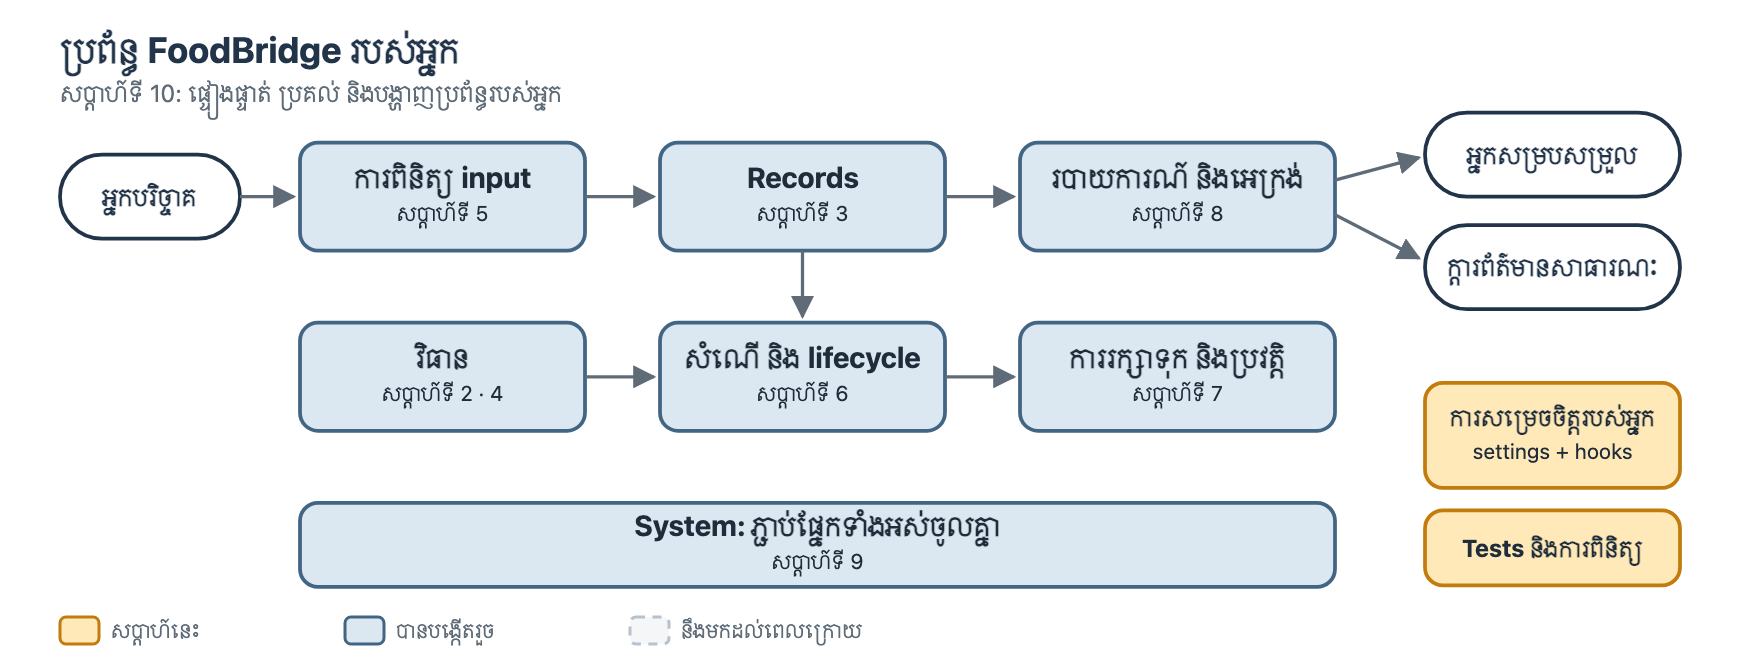

## 0 · ចាប់ផ្ដើម

1. **File → Save a copy in Drive** បន្ទាប់មកធ្វើការក្នុងច្បាប់ចម្លងរបស់អ្នក។
2. Run setup cell។ Run វាម្ដងទៀត រាល់ពេល runtime restart។
3. ធ្វើការពីលើចុះក្រោម។ មុនពេលដាក់ស្នើ សូមប្រើ **Runtime → Restart session and run all**។

In [ ]:
# @title ▶ សូម run cell នេះមុនគេ (setup) — វារៀបចំប្រព័ន្ធ FoodBridge
# វាដកយក (unpack) ប្រព័ន្ធរបស់វគ្គសិក្សា ដែលរក្សាទុកនៅក្នុង notebook នេះ។
# មិនត្រូវការ internet ឬ install អ្វីទេ។ សូម run វាម្ដងទៀត ក្រោយពេល Colab restart។
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.3"
_KIT_SHA = "9a7f0e70ab94bb1480312c1ccc2cd08ea21038ab8fa51cc0adbfe520961d0844"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("ឯកសាររបស់វគ្គសិក្សាក្នុង notebook នេះខូច។ សូមទាញយកច្បាប់ថ្មីមួយ។")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
bridge.set_language("km")     # screens and checks in Khmer
print("✅ ប្រព័ន្ធ FoodBridge រួចរាល់ហើយ (version " + bridge.KIT_VERSION + ")។ អ្នកអាចបន្តបាន។")


## កម្រិតទី 1 · Run ប្រព័ន្ធ ⭐

នេះជាប្រព័ន្ធទាំងមូល ជាមួយ default settings។ គ្មានអ្វីនៅទីនេះប្រើ code របស់អ្នកនៅឡើយទេ ដូច្នេះវាមិនអាចខូចបានទេ។

In [ ]:
system = bridge.System()
system.run_day()

អ្នកប្រើពីរប្រភេទ ប្រើប្រព័ន្ធនេះ ហើយឃើញអ្វីៗខុសគ្នា។ សូមអានទិដ្ឋភាពទាំងពីរ។

In [ ]:
print(system.report("coordinator"))
print()
print(system.report("public"))

`verify()` run ការពិនិត្យរបស់ kit ផ្ទាល់។ គ្រប់បន្ទាត់ក្នុងផ្នែកទីមួយ ត្រូវតែបង្ហាញ ✅។

In [ ]:
system.verify()

📝 **កម្រិតទី 1 · ជាពាក្យរបស់អ្នកផ្ទាល់** (2–3 ប្រយោគ): តើអ្នកណាប្រើប្រព័ន្ធនេះ វារក្សាទុកទិន្នន័យអ្វីខ្លះ ហើយវិធានមួយដែលវាធ្វើតាមគឺអ្វី?

**ចម្លើយរបស់ខ្ញុំ:** …

## កម្រិតទី 2 · ធ្វើឱ្យជារបស់អ្នក ⭐

### ការសម្រេចចិត្តរបស់អ្នក

ខាងក្រោមនេះជា **ការសម្រេចចិត្តទាំងអស់** ដែលប្រព័ន្ធអនុញ្ញាតឱ្យអ្នកប្ដូរ ជាមួយសប្ដាហ៍ដែលអ្នកបានជួបវា (ពីរជារបស់ថ្មី: `PARTNERS` និង `LANGUAGE`)។ លុប `#` នៅខាងមុខបន្ទាត់មួយ ដើម្បីប្ដូរវា។

អ្នកត្រូវធ្វើការសម្រេចចិត្ត **យ៉ាងហោចណាស់ 3**: ប្ដូរ value មួយ ឬរក្សា default ដោយចេតនា ហើយពន្យល់ហេតុផល។ **យ៉ាងហោចណាស់មួយ** ត្រូវតែទាក់ទងនឹង **ឯកជនភាព** (`PUBLIC_FIELDS`) ឬ **ការពិនិត្យ input** (`REQUIRED_FIELDS`, `MIN_PORTIONS`, `MAX_PORTIONS`, `REJECT_IF_HOURS_LEFT_BELOW`, `CATEGORIES`)។ `SYSTEM_NAME` គ្រាន់តែជាឈ្មោះ: ប្ដូរវាបើអ្នកចង់ ប៉ុន្តែវាមិនរាប់ជាការសម្រេចចិត្តមួយ ក្នុងចំណោម 3 របស់អ្នកទេ។

In [ ]:
MY_SETTINGS = {
    "SYSTEM_NAME": "Campus FoodBridge",                    # សប្ដាហ៍ទី 1 · គ្រាន់តែជាឈ្មោះ (មិនមែនជាការសម្រេចចិត្ត)
    # "TEAM_PICKUP_MIN_PORTIONS": 20,                       # សប្ដាហ៍ទី 2 · ចំណែកចំនួននេះ ឬច្រើនជាង → team
    # "URGENT_HOURS": 3,                                    # សប្ដាហ៍ទី 2 · ម៉ោងនៅសល់ស្មើ ឬតិចជាងនេះ → urgent
    # "SOON_HOURS": 12,                                     # សប្ដាហ៍ទី 2 · ម៉ោងនៅសល់ស្មើ ឬតិចជាងនេះ → soon
    # "CATEGORIES": ["bread", "rice meals", "fruit", "vegetables", "snacks"],  # សប្ដាហ៍ទី 3
    # ថ្មី · អង្គការដៃគូដែលអ្នកសម្របសម្រួលអាចជ្រើសរើស:
    # "PARTNERS": ["Hope Children's Centre", "Riverside Community Kitchen", "Old Market Elders' Group"],
    # "REQUIRED_FIELDS": ["donor", "food", "category", "portions", "hours_left"],  # សប្ដាហ៍ទី 5
    # "MIN_PORTIONS": 1,                                    # សប្ដាហ៍ទី 5
    # "MAX_PORTIONS": 200,                                  # សប្ដាហ៍ទី 5
    # "REJECT_IF_HOURS_LEFT_BELOW": 1,                      # សប្ដាហ៍ទី 5 · យឺតពេកក្នុងការទៅយក
    # "REQUIRE_APPROVAL": True,                             # សប្ដាហ៍ទី 6 · អ្នកសម្របសម្រួលអនុម័តជាមុនសិន
    # "LOG_EVENTS": ["added", "input_rejected", "moved"],   # សប្ដាហ៍ទី 7 · អ្វីដែលប្រវត្តិរក្សាទុក
    # "PUBLIC_FIELDS": ["id", "food", "category", "portions", "status"],  # សប្ដាហ៍ទី 8 · ឯកជនភាព
    # "REPORT_SORT": "urgency",                             # សប្ដាហ៍ទី 8 · "urgency", "portions" ឬ "id"
    # "LANGUAGE": "en",                                     # ថ្មី · "en" ពាក្យអង់គ្លេស ឬ "km" ពាក្យខ្មែរ ("km" ជា default ក្នុង notebook នេះ)
}

### Function របស់អ្នក (ស្រេចចិត្តនៅកម្រិតទី 2 ប៉ុន្តែត្រូវការសម្រាប់កម្រិតទី 3)

បើអ្នកបានបញ្ចប់ function នៅសប្ដាហ៍ទី 2–8 អ្នកអាចភ្ជាប់វាចូល ជា **hook**។ Paste (បិទភ្ជាប់) function មួយទៅក្នុង cell ខាងក្រោម ជាមួយ helper ឬ dictionary ណាដែលវាប្រើ បន្ទាប់មកបន្ថែមវាទៅក្នុង `MY_HOOKS`។ បើអ្នកទុក `MY_HOOKS` ទទេ ប្រព័ន្ធប្រើវិធាន default ផ្ទាល់របស់វា ហើយនោះមិនអីទេ សម្រាប់កម្រិតទី 2។

យកលេខនីមួយៗពី `ALL_SETTINGS` (cell បង្កើតវាឱ្យអ្នក: settings របស់អ្នក បូកនឹង default)។ **លុបបន្ទាត់ `NAME = value` ណាមួយដែលអ្នក paste** ពីសប្ដាហ៍មុនៗ ដូចជា `TEAM_PICKUP_MIN_PORTIONS = 20`។ បើមិនដូច្នោះទេ function របស់អ្នក និង settings របស់អ្នក អាចមិនស៊ីគ្នា។

| Hook | សប្ដាហ៍ | អ្វីដែលវាសម្រេច |
|---|---|---|
| `pickup_label(portions, approved)` | 2 | hold, team ឬ standard |
| `urgency(hours_left)` | 2 | urgent, soon ឬ later |
| `clean_offer(raw)` | 5 | ទទួល ឬបដិសេធសំណើមួយ ជាមួយសារ |
| `can_move(old_status, new_status)` | 6 | ការប្ដូរ status ណាខ្លះដែលអនុញ្ញាត |
| `public_row(record)` | 8 | អ្វីដែលក្ដារព័ត៌មានសាធារណៈបង្ហាញ |

In [ ]:
ALL_SETTINGS = bridge.make_settings(MY_SETTINGS, quiet=True)  # setting នីមួយៗ: របស់អ្នក ឬ default

# Paste function របស់អ្នកនៅទីនេះ ជាមួយ helper ដែលវាប្រើ ឧទាហរណ៍:
#
# TEAM_PICKUP_MIN_PORTIONS = ALL_SETTINGS["TEAM_PICKUP_MIN_PORTIONS"]   # ពី settings របស់អ្នក
#
# def pickup_label(portions, approved):
#     ...

MY_HOOKS = {
    # "pickup_label": pickup_label,
}

### Run ប្រព័ន្ធរបស់អ្នក

In [ ]:
my_system = bridge.System(MY_SETTINGS, hooks=MY_HOOKS)
my_system.run_day()
print(my_system.report("coordinator"))
print()
print(my_system.report("public"))

ឥឡូវ `verify()` ក៏រាយការណ៍អំពីប្រព័ន្ធ **របស់អ្នក** ដែរ: អ្វីដែលអ្នកបានប្ដូរ hook ណាខ្លះដែលបានភ្ជាប់ និងការព្រមានណាមួយ។ ផ្នែកទីពីរ មិនមែនជាការជាប់ ឬធ្លាក់ទេ។ វានៅទីនោះ ដើម្បីឱ្យអ្នកអាចពន្យល់វាបាន។

In [ ]:
my_system.verify()

### សាកល្បងសំណើមួយ

ការសម្រេចចិត្តខ្លះ មិនប្ដូរអ្វីទាំងអស់ក្នុងថ្ងៃគំរូ។ ឧទាហរណ៍ អប្បបរមាសម្រាប់ក្រុម 25 ផ្ដល់ស្លាកដូចគ្នានឹង 20 ព្រោះគ្មានសំណើដែលមិនទាន់បញ្ចប់ណាមួយ មានចំណែករវាង 20 និង 24 ទេ។ ដូច្នេះ សូមសាកល្បង **សំណើមួយរបស់អ្នកផ្ទាល់**។ cell ខាងក្រោម បន្ថែមវាទៅក្នុងប្រព័ន្ធ test ថ្មីទទេមួយ ពីរដង: ម្ដងជាមួយ default settings ម្ដងទៀតជាមួយ settings របស់អ្នក។ ប្រព័ន្ធពិតរបស់អ្នក មិនប្រែប្រួលទេ។

ប្ដូរ value ក្នុង `try_row` រហូតដល់បន្ទាត់ទាំងពីរខុសគ្នា ដោយសារការសម្រេចចិត្ត **របស់អ្នក**។ គំនិត: ចំណែករវាង 20 និងអប្បបរមាក្រុមរបស់អ្នក · ចំណែកលើស `MAX_PORTIONS` របស់អ្នក · ប្រភេទដែលអ្នកបានដកចេញ · ម៉ោងនៅសល់ស្មើនឹង `URGENT_HOURS` របស់អ្នក។

In [ ]:
def try_offer(settings, hooks, row):
    """Add one row to a new, empty test system, approve it, and say what happened."""
    test_system = bridge.System(settings, hooks=hooks, quiet=True)
    offer_id, errors = test_system.add_offer(row)
    if offer_id is None:
        return "refused: " + " ".join(errors)
    offer = test_system.get(offer_id)
    before = test_system.label(offer)
    test_system.move(offer_id, "approved", partner=test_system.settings["PARTNERS"][0])
    return ("accepted · urgency: " + test_system.urgency(offer)
            + " · pickup: " + before + ", after approval: " + test_system.label(offer))

In [ ]:
try_row = {"donor": "Test Donor", "contact": "test@example.org", "food": "Rice boxes",
           "category": "rice meals", "portions": "22", "hours_left": "6"}

print("Default system:", try_offer({}, {}, try_row))
print("My system:     ", try_offer(MY_SETTINGS, MY_HOOKS, try_row))

🤔 ប្រៀបធៀបជាមួយកម្រិតទី 1 ហើយប្រើ **សាកល្បងសំណើមួយ**។ តើសំណើណាដែលត្រូវបានចាត់ចែងខុសគ្នា ដោយសារការសម្រេចចិត្តរបស់អ្នក? ចង្អុលទៅបន្ទាត់មួយក្នុងលទ្ធផល។

**ចម្លើយរបស់ខ្ញុំ:** …

### 📝 កំណត់ត្រាការសម្រេចចិត្ត (decision log)

មួយជួរ សម្រាប់ការសម្រេចចិត្តមួយ។ កំណត់ត្រាដែលរឹងមាំ បញ្ជាក់ **value ជាក់លាក់មួយ** **ជម្រើសផ្សេងពិតប្រាកដមួយ** **មូលហេតុដែលទាក់ទងនឹងមនុស្ស** និង **អ្នកដែលរងផលប៉ះពាល់** (ការដោះដូរ)។

| Setting | Value របស់ខ្ញុំ | ជម្រើសផ្សេងដែលខ្ញុំបានពិចារណា | ហេតុអ្វីខ្ញុំជ្រើសវា | អ្នកណារងផលប៉ះពាល់ (ការដោះដូរ) |
|---|---|---|---|---|
| | | | | |
| | | | | |
| | | | | |

<details><summary>មើលឧទាហរណ៍នៃកំណត់ត្រាដែលរឹងមាំ</summary>

| Setting | Value របស់ខ្ញុំ | ជម្រើសផ្សេងដែលខ្ញុំបានពិចារណា | ហេតុអ្វីខ្ញុំជ្រើសវា | អ្នកណារងផលប៉ះពាល់ (ការដោះដូរ) |
|---|---|---|---|---|
| `PUBLIC_FIELDS` | id, food, portions, status | បង្ហាញ `category` ផងដែរ | អង្គការដៃគូគ្រាន់តែត្រូវដឹងថា អាហារអ្វីកំពុងមក និងប៉ុន្មាន។ field កាន់តែតិច មានរបស់កាន់តែតិចដែលអាចលេចធ្លាយ។ | អង្គការដៃគូមិនអាចត្រងតាមប្រភេទបានទេ; ព័ត៌មានរបស់អ្នកបរិច្ចាគ នៅតែជាឯកជន។ |

កំណត់ត្រាដែលខ្សោយ និយាយតែថា "ខ្ញុំប្ដូរវាទៅ 25 ព្រោះវាល្អជាង"។ ល្អជាងសម្រាប់នរណា ហើយបាត់បង់អ្វី?

</details>

## កម្រិតទី 3 · ពង្រីក ⭐⭐ (ស្រេចចិត្ត)

បន្ថែមអ្វីមួយដែលប្រព័ន្ធមិនទាន់ធ្វើ ហើយ **ការពារវាដោយ test**។ ជ្រើសរើសគំនិតមួយ ឬគំនិតរបស់អ្នកផ្ទាល់:

- **វិធានដែលឆ្លាតជាងមុន:** hook `pickup_label` ឬ `urgency` ដែលប្រើ value មួយទៀតដែលអ្នកសម្រេច ដោយសរសេរជាមួយ constant ដែលមានឈ្មោះ។
- **ការពិនិត្យដែលតឹងរ៉ឹងជាងមុន:** hook `clean_offer` ដែលបដិសេធអ្វីមួយថ្មី (ឧទាហរណ៍ ឈ្មោះអាហារដែលខ្លីជាង 3 អក្សរ) ជាមួយសារច្បាស់លាស់។ អ្នកមិនចាំបាច់សរសេរសប្ដាហ៍ទី 5 ឡើងវិញទេ: ចាប់ផ្ដើមពីការពិនិត្យរបស់ kit ផ្ទាល់ ហើយបន្ថែមវិធានមួយ (មើលខាងក្រោម)។
- **លេខដែលស្មោះត្រង់:** function របាយការណ៍មួយ ដូចជា `rejected_or_cancelled_percent(records)`: តើសំណើប៉ុន្មានភាគរយ ត្រូវបានបដិសេធ ឬលុបចោល? (ជួរដែល *ត្រូវបដិសេធនៅមាត់ទ្វារ* ជារង្វាស់ផ្សេង: វាមិនដែលក្លាយជាសំណើទេ។)
- **Status ថ្មី:** បន្ថែម state មួយ ដូចជា `"reserved"` ទៅក្នុង `ALLOWED_MOVES` និង `can_move` ផ្ទាល់ខ្លួនរបស់អ្នក ហើយពន្យល់ថាអ្នកណានឹងប្រើវា។ ⚠️ **ដែនកំណត់ដែលដឹងហើយ:** របាយការណ៍របស់ kit ស្គាល់តែ status ទាំង 6។ សំណើដែល reserved បាត់ពីទិដ្ឋភាពអ្នកសម្របសម្រួល និងពី *ចំណែកដែលមិនទាន់បញ្ចប់*។ សរសេរ test មួយដែលបង្ហាញរឿងនេះ (មើលខាងក្រោម) ហើយសរសេរវានៅក្រោម *ដែនកំណត់ដែលដឹងហើយ* ក្នុងកំណត់ចំណាំប្រគល់ការងាររបស់អ្នក។

<details><summary>មើលការចាប់ផ្ដើម សម្រាប់ការពិនិត្យដែលតឹងរ៉ឹងជាងមុន</summary>

```python
def clean_offer(raw):
    """The kit's checks (with my settings), plus one rule of my own."""
    offer, errors = bridge.validation.clean_offer(raw, ALL_SETTINGS)
    if offer is not None and len(offer["food"]) < 3:
        return None, ["food name must have at least 3 letters."]
    return offer, errors
```

`ALL_SETTINGS` មកពី hook cell ក្នុងកម្រិតទី 2។ បន្ថែម `"clean_offer": clean_offer` ទៅក្នុង `MY_HOOKS` run `bridge.check("clean_offer", clean_offer, MY_SETTINGS)` ហើយសរសេរ test ពីរ: ឈ្មោះអាហារ 3 អក្សរ ត្រូវបានទទួល ឈ្មោះ 2 អក្សរ ត្រូវបានបដិសេធ។

</details>

<details><summary>មើល test សម្រាប់ដែនកំណត់ "reserved"</summary>

```python
def test_reserved_offer_leaves_the_coordinator_view():
    system = bridge.System(hooks={"can_move": can_move}, quiet=True)  # can_move របស់អ្នក ដែលមាន "reserved"
    system.run_day(show=False)
    ok, message = system.move("F004", "reserved")
    assert ok, "my lifecycle allows approved -> reserved: " + message
    report = system.report("coordinator")
    assert "F004" not in report, "known limit: the coordinator view shows only new, approved and picked_up"
```

test នេះជាប់ ដរាបណាដែនកំណត់នៅមាន។ វាមិនលាក់បញ្ហាទេ: វា **កត់ត្រាទុក** បញ្ហានោះ ដើម្បីឱ្យមនុស្សបន្ទាប់ដឹង។

</details>

សរសេរ function របស់អ្នក បន្ទាប់មកសរសេរ function `test_` យ៉ាងហោចណាស់ **ពីរ** (ករណីធម្មតាមួយ និងករណី boundary ឬករណីចម្លែកមួយ)។ ដាក់ test របស់អ្នកក្នុង list `MY_TESTS`; cell បន្ទាប់ run test នីមួយៗ ដូចក្នុងសប្ដាហ៍ទី 10។ test ដែលមិនទាន់សរសេរ បង្ហាញ ❌ ដោយចេតនា។

In [ ]:
def rejected_or_cancelled_percent(records):
    """Return the share of offers that were rejected or cancelled, as a whole percentage."""
    return None   # TODO (ឬជំនួសវាដោយគំនិតរបស់អ្នកផ្ទាល់)


def test_percent_on_sample_records():
    assert False, "not written yet: use bridge.sample_records()"


def test_percent_on_empty_list():
    assert False, "not written yet: what should an empty list give?"


MY_TESTS = [test_percent_on_sample_records, test_percent_on_empty_list]
print(rejected_or_cancelled_percent(my_system.records()))

In [ ]:
for test in MY_TESTS:
    try:
        test()
        print("✅", test.__name__)
    except Exception as error:
        print("❌", test.__name__, "→", type(error).__name__ + ":", error)
print(len(MY_TESTS), "tests run.")

📝 **កម្រិតទី 3 · អ្វីដែលខ្ញុំបានបន្ថែម និងហេតុអ្វី** (អ្នកណាត្រូវការវា អ្វីដែលអ្នកបាន test ដែនកំណត់មួយ):

**ចម្លើយរបស់ខ្ញុំ:** …

## កម្រិតទី 4 · ទំព័រ web ⭐⭐ (ស្រេចចិត្ត)

### 4a · បើកប្រព័ន្ធរបស់អ្នកជាទំព័រ web

លុប `#` ហើយ run cell។ ក្នុង Colab នឹងមាន link មួយលេចឡើង: ចុចវា ដើម្បីបើកប្រព័ន្ធរបស់អ្នកក្នុង tab ថ្មី។ ទំព័រនេះប្រើ settings និង hook **របស់អ្នក**។ សាកល្បងបន្ថែមសំណើមួយដែលមាន input មិនល្អ និងប្ដូរសំណើមួយទៅ status ដែលមិនអនុញ្ញាត។

In [ ]:
# bridge.start_web(my_system)

ទំព័រនេះនៅតែដំណើរការ ដរាបណា notebook នៅបើក។ បើអ្នក run 4a ម្ដងទៀត វាចាប់ផ្ដើមឡើងវិញ ជាមួយប្រព័ន្ធចុងក្រោយរបស់អ្នក។ ដើម្បីបញ្ឈប់វា លុប `#` ខាងក្រោម ហើយ run cell។ បន្ទាប់មកដាក់ `#` ត្រឡប់វិញ។

In [ ]:
# bridge.stop_web()

### 4b · ទាញយកប្រព័ន្ធរបស់អ្នក ហើយ run វានៅផ្ទះ

cell នេះបង្កើត ZIP នៃប្រព័ន្ធទាំងមូល ដែលការសម្រេចចិត្ត **របស់អ្នក** ត្រូវបានសរសេរទៅក្នុង `my_settings.py` ហើយ hook របស់អ្នក ទៅក្នុង `my_rules.py`។ លុប `#` ហើយ run វា។

In [ ]:
# bridge.download_my_system(MY_SETTINGS, MY_HOOKS)

**នៅលើកុំព្យូទ័រផ្ទាល់ខ្លួនរបស់អ្នក** (Python 3.9 ឬថ្មីជាងនេះ; មិនចាំបាច់ install អ្វីទេ):

1. Unzip `my_foodbridge.zip`។
2. បើក terminal ក្នុង folder `foodbridge_kit`។
3. Run `python run_web.py` (លើកុំព្យូទ័រខ្លះ `python3 run_web.py`) ហើយបើក http://localhost:8000។
4. Command ផ្សេងទៀត: `python run_menu.py` (menu ជាអក្សរ) `python run_tests.py` (test របស់ kit)។

**ក្នុង terminal របស់ Colab** (បើ Colab របស់អ្នកមានប៊ូតុង **Terminal** នៅខាងក្រោមផ្នែកខាងឆ្វេង):

1. Run 4b ជាមុនសិន។ វាសរសេរ `my_foodbridge.zip` ទៅក្នុងផ្ទាំង Files រួចហើយ (📁 នៅខាងឆ្វេង) ដូច្នេះអ្នកមិនចាំបាច់ upload អ្វីទេ។
2. ក្នុង terminal វាយ command ទាំងនេះម្ដងមួយៗ: `unzip -o -q my_foodbridge.zip -d home_copy` បន្ទាប់មក `cd home_copy/foodbridge_kit` បន្ទាប់មក `python run_menu.py`។
3. សម្រាប់ទំព័រ web: បើអ្នកបាន run 4a សូម run `bridge.stop_web()` ក្នុង notebook ជាមុនសិន។ បន្ទាប់មកវាយ `python run_web.py` ក្នុង terminal (នៅតែក្នុង `home_copy/foodbridge_kit`)។ បន្ទាប់មកលុប `#` ក្នុង cell ខាងក្រោម run វា ហើយចុច link។ បើ `run_web.py` print លេខ port ផ្សេង សូមប្រើលេខនោះជំនួស 8000។

In [ ]:
# bridge.web_link(8000)

សំណើដែលអ្នកបានរក្សាទុក ស្ថិតនៅក្នុង folder `saved_data` នៅជាប់នឹង `run_web.py`។ ដើម្បីចាប់ផ្ដើមថ្ងៃថ្មី សូម run `python run_web.py --fresh` (ឬ `python run_menu.py --fresh`)។

## 5 · ផ្ទៀងផ្ទាត់ និងប្រគល់ ⭐

ប្រព័ន្ធមួយបញ្ចប់ ពេល **អ្នកផ្សេង** អាច run វា ហើយទុកចិត្តវាបាន។

1. **Runtime → Restart session and run all**។ cell នីមួយៗគួរតែ run ពីលើចុះក្រោម ដោយគ្មាន error។
2. Paste test ការសម្រេចចិត្តពីររបស់អ្នក ពីសប្ដាហ៍ទី 10 ទៅក្នុង **Test សម្រាប់ការសម្រេចចិត្តរបស់ខ្ញុំ**។ ទាំងពីរត្រូវតែបង្ហាញ ✅។
3. Run **ការពិនិត្យចុងក្រោយ** ម្ដងចុងក្រោយ។

### Test សម្រាប់ការសម្រេចចិត្តរបស់ខ្ញុំ

Helper ទាំងនេះ ដូចគ្នានឹងក្នុងសប្ដាហ៍ទី 10។ Run cell នេះ; អ្នកមិនចាំបាច់ប្ដូរវាទេ។

In [ ]:
ALL_SETTINGS = bridge.make_settings(MY_SETTINGS, quiet=True)  # setting នីមួយៗ: របស់អ្នក ឬ default


def fresh_system():
    """Return a new system with my settings and hooks, after the sample day."""
    system = bridge.System(MY_SETTINGS, hooks=MY_HOOKS, quiet=True)
    system.run_day(show=False)
    return system


def offer_row(system, portions):
    """Return a raw offer row that passes every input check (portions may be changed)."""
    return {"donor": "Test Donor", "contact": "test@example.org", "food": "Test rice",
            "category": system.settings["CATEGORIES"][0], "portions": str(portions),
            "hours_left": "8"}


def approved_offer(system, portions):
    """Add a test offer, approve it for the first partner, and return the Offer."""
    offer_id, errors = system.add_offer(offer_row(system, portions))
    assert offer_id is not None, "the test offer was refused: " + "; ".join(errors)
    system.move(offer_id, "approved", partner=system.settings["PARTNERS"][0])
    return system.get(offer_id)


def run_tests(tests):
    passed = 0
    for test in tests:
        try:
            test()
            print("✅", test.__name__)
            passed = passed + 1
        except Exception as error:
            print("❌", test.__name__, "→", type(error).__name__ + ":", error)
    print(passed, "of", len(tests), "tests passed")

Paste test ពីរដែលអ្នកបានសរសេរក្នុងសប្ដាហ៍ទី 10 (P2) ទៅក្នុង cell ខាងក្រោម ជំនួស test ទុកកន្លែង (placeholder) ទាំងពីរ។ បន្ទាប់មកដាក់ឈ្មោះរបស់វាក្នុង `MY_DECISION_TESTS`។ test នីមួយៗការពារការសម្រេចចិត្តមួយ **របស់អ្នក**។ test ដែលមិនទាន់សរសេរ បង្ហាញ ❌ ដោយចេតនា។

In [ ]:
def test_my_decision_one():
    system = fresh_system()
    assert False, "not written yet: paste your first Week 10 test here"


def test_my_decision_two():
    system = fresh_system()
    assert False, "not written yet: paste your second Week 10 test here"


MY_DECISION_TESTS = [test_my_decision_one, test_my_decision_two]
run_tests(MY_DECISION_TESTS)

### ការពិនិត្យចុងក្រោយ

`verify()` ពិនិត្យ kit បន្ទាប់មករាយការណ៍អំពីប្រព័ន្ធ **របស់អ្នក**។ អានផ្នែកទីពីរ (*ប្រព័ន្ធរបស់អ្នក*): ⚠️ នីមួយៗ ត្រូវការមួយប្រយោគ ក្នុងកំណត់ចំណាំប្រគល់ការងាររបស់អ្នក។

In [ ]:
final_system = bridge.System(MY_SETTINGS, hooks=MY_HOOKS)
final_ok = final_system.verify()
print()
if final_ok:
    print("Next: read 'Your system' above, and explain every ⚠️ in your handoff note.")
else:
    print("❌ The kit itself is damaged: get a fresh copy of this notebook.")
changed = bridge.settings.changed_settings(final_system.settings)
print("Settings you changed:", ", ".join(changed) or "none")
print("Your hooks:", ", ".join(final_system.custom_hooks()) or "none (default rules)")

### 📝 កំណត់ចំណាំប្រគល់ការងារ

សរសេរវាសម្រាប់អ្នកសម្របសម្រួលថ្មីម្នាក់ ដែលមិនដែលឃើញ notebook របស់អ្នក។ អ្នកបានសរសេរព្រាងវានៅសប្ដាហ៍ទី 10; ចម្លងអត្ថបទចុងក្រោយមកទីនេះ។

| | |
|---|---|
| **អ្វីដែលប្រព័ន្ធរបស់ខ្ញុំធ្វើ** (2 ប្រយោគ: អ្នកណាប្រើវា សម្រាប់អ្វី) | |
| **របៀប run វា** (ជំហានដាក់លេខរៀង; ប្រាប់ថាអ្នក run គួរឃើញអ្វីនៅចុងបញ្ចប់) | 1. <br> 2. <br> 3. |
| **ការសម្រេចចិត្តរបស់ខ្ញុំ** (3 ដែលសំខាន់បំផុត: setting, value និងហេតុអ្វី) | |
| **អ្វីដែលខ្ញុំបាន test និងរបៀប** (test ការសម្រេចចិត្តរបស់ខ្ញុំ ការ run ស្អាត) | |
| **ដែនកំណត់ដែលដឹងហើយ** (អ្វីដែលវាមិនធ្វើ; ⚠️ ណាមួយ និងហេតុអ្វីវាអាចទទួលយកបាន) | |

### 📝 កំណត់ត្រា peer test (សប្ដាហ៍ទី 10 វគ្គទី 2)

មិត្តរួមថ្នាក់ម្នាក់ (operator) run ប្រព័ន្ធរបស់អ្នក ដោយប្រើតែកំណត់ចំណាំប្រគល់ការងាររបស់អ្នកប៉ុណ្ណោះ។ អ្នកមើល ហើយមិនជួយទេ។ ចម្លងសេចក្ដីសង្ខេបខ្លី នៃកំណត់ត្រារបស់ operator មកទីនេះ។

| | |
|---|---|
| **ឈ្មោះ operator** | |
| **តើគេអាច run វា ដោយប្រើតែកំណត់ចំណាំបានទេ? តើអ្នកត្រូវនិយាយឬទេ?** | |
| **ការលំបាកដំបូងគេ** | |
| **លទ្ធផលនៃ `verify()` នៅចុងបញ្ចប់** | |
| **ការកែប្រែមួយ ដែលអ្នកបានធ្វើលើកំណត់ចំណាំ** | |
| **បាន test ឡើងវិញក្រោយការកែប្រែទេ? លទ្ធផល** | |

## 6 · ដាក់ស្នើ (submit)

- [ ] កម្រិតទី 1: `verify()` បង្ហាញ ✅ សម្រាប់ការពិនិត្យ kit នីមួយៗ។
- [ ] កម្រិតទី 2: ការសម្រេចចិត្តយ៉ាងហោចណាស់ 3 ក្នុង `MY_SETTINGS` (មួយអំពីឯកជនភាព ឬការពិនិត្យ input; `SYSTEM_NAME` មិនរាប់ទេ) និងជួរកំណត់ត្រាការសម្រេចចិត្តមួយ សម្រាប់នីមួយៗ។
- [ ] កម្រិតទី 3 (ស្រេចចិត្ត): function របស់ខ្ញុំ និង test យ៉ាងហោចណាស់ពីរ ដែលទាំងអស់ ✅។
- [ ] កម្រិតទី 4 (ស្រេចចិត្ត): ខ្ញុំបានបើកទំព័រ web ឬបាន run ប្រព័ន្ធរបស់ខ្ញុំពី ZIP។
- [ ] 5: test ការសម្រេចចិត្តពីររបស់ខ្ញុំបង្ហាញ ✅; បំពេញកំណត់ចំណាំប្រគល់ការងារ និងកំណត់ត្រា peer test រួច; បានធ្វើ **Runtime → Restart session and run all** មុនពេលរក្សាទុក។

ទាញយក notebook នេះ (**File → Download → Download .ipynb**) ហើយ email វាទៅ **submit.progmis@gmail.com**។ ថ្ងៃផុតកំណត់ និងឈ្មោះ file នឹងប្រកាសនៅក្នុងថ្នាក់។

**បទបង្ហាញ (សប្ដាហ៍ទី 10 វគ្គទី 2, 3 នាទី):** មនុស្ស និងបញ្ហា · ការសម្រេចចិត្តរបស់អ្នក · demo ខ្លីមួយ · អ្វីដែលអ្នកបាន test · អ្វីដែលអ្នកនឹងកែលម្អបន្ទាប់។